# E86 · GPU ensembles: ChEES-HMC and MEADS on a forest of 20,000 cells

| | |
|---|---|
| **Type** | Advanced worked example - read, run, modify |
| **Data** | Real: the 3,604 *Beilschmiedia pendula* trees of the Barro Colorado Island 50-ha plot, with elevation and slope on a 5 m grid (`spatstat.data`; Hubbell & Foster 1983, Condit et al. 1996) |
| **Time** | About 10 minutes with a GPU; about 6 minutes on 8 CPU cores, where it switches to a coarser 20 m lattice |
| **You will learn** | Which steps of Bayesian sampling a GPU speeds up and which it does not · why NUTS is awkward on a GPU · running **ChEES-HMC** and **MEADS** from `blackjax` on a PyMC model · why **float32** matters on a consumer GPU · how one bad chain can ruin an ensemble, and how to catch it · how to give a baseline a fair chance |

## The brief

A forest ecologist has mapped every *Beilschmiedia pendula* tree in a 1000 x 500 m plot and has
two questions. **Does the species' link to terrain hold across the whole plot, or only in parts of
it?** And **which five hectares should a recruitment survey use**, if the aim is the best habitat
rather than wherever a clump of trees happens to stand?

Answering the first needs effects that vary over space. Answering both means separating habitat
from the fine clustering of a species whose seeds fall near their parents. That is a log-Gaussian
Cox process with four latent fields on a 5 m lattice: 20,000 cells and 24,810 parameters. It is
also a fair test of a GPU, because every gradient is a stack of dense matrix products.

## The idea

A GPU does thousands of identical operations at once. One NUTS chain cannot use that: each step depends on the one
before it. But **many chains** can, because a gradient for 128 chains is one big batched matrix product. That moves
the bottleneck, as Hoffman et al. point out: with many chains, ESS is plentiful and the limit is how fast the chains
reach and mix through the posterior. ChEES-HMC and MEADS tune their settings from the ensemble itself, so that all
chains can take the same number of steps in lock-step.

All timings quoted below come from one desktop: an NVIDIA RTX 3090 Ti and a 16-core Ryzen 5950X
running on 15 cores. On a CPU-only machine the notebook runs a smaller problem and skips the GPU
comparisons, so your printed numbers will differ from the prose, and the committed outputs are the
place to see those comparisons. GPU runs are not bit-reproducible, so even with the same seed,
numbers move between runs: the prose gives ranges or rounded values.

## The plan

1. The trees, the terrain and the model
2. The baseline: NUTS on the CPU
3. Where the time goes: chains, problem size and precision
4. ChEES-HMC: two ways to fail, and a fix
5. Why not just run NUTS on the GPU?
6. MEADS: fragile from a cold start, excellent from a warm one
7. The scorecard, and how much of it is the hardware
8. Is single precision safe?
9. Back to the forest
10. Which steps does a GPU speed up?

In [1]:
import os

os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")  # before NumPy: one BLAS thread per nutpie chain

import contextlib
import importlib.util
import logging
import tempfile
import time
import warnings

import arviz as az
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import nutpie
import pandas as pd
import pymc as pm
import pytensor
import pytensor.tensor as pt
import xarray as xr
from jax.flatten_util import ravel_pytree
from pymc.sampling.jax import get_jaxified_graph, get_jaxified_logp

from pymc_challenges import data

RANDOM_SEED = 86
rng = np.random.default_rng(RANDOM_SEED)
az.style.use("arviz-variat")
warnings.filterwarnings("ignore", message=".*Explicitly requested dtype.*")
warnings.filterwarnings("ignore", message=".*truncated to dtype float32.*")
logging.getLogger("pymc").setLevel(logging.WARNING)

# Asking JAX for its backend would start CUDA, and the CPU baseline comes first. So does importing blackjax, which
# touches a JAX array when it loads: its import waits until after the baseline, against the usual first-cell habit.
HAS_GPU = (importlib.util.find_spec("jax_cuda13_plugin") is not None
           and any(os.path.exists(d) for d in ("/dev/nvidia0", "/dev/nvidiactl", "/dev/dxg"))
           and os.environ.get("JAX_PLATFORMS") != "cpu")
CORES = len(os.sched_getaffinity(0)) if hasattr(os, "sched_getaffinity") else os.cpu_count()
NUTS_CHAINS = min(8, max(4, CORES // 2 - 1))  # one on each physical core, capped to keep the build under 5 GB
NUTS_DRAWS = 4000 // NUTS_CHAINS               # 4,000 draws in total
L_SMOOTH = 800.0  # half-width of the box for the smooth fields: far enough from the plot for their lengthscales
# The full problem on a GPU; a coarser lattice on a CPU, which keeps the same code within budget.
if HAS_GPU:
    CELL, M_FINE, M_SMOOTH = 5.0, (100, 200), (40, 40)
    CHAINS, WARMUP, SNAPS, KEEP = 128, 1000, 30, 10
    MEADS_WARMUP, MEADS_KEEP, MEADS_THIN = 20_000, 13, 100
else:
    CELL, M_FINE, M_SMOOTH = 20.0, (25, 50), (20, 20)
    CHAINS, WARMUP, SNAPS, KEEP = 64, 500, 20, 5  # MEADS needs at least 16 chains per fold here: see section 6
    MEADS_WARMUP, MEADS_KEEP, MEADS_THIN = 10_000, 10, 100
print(f"GPU build of JAX: {HAS_GPU}; lattice {CELL:.0f} m, {CHAINS} chains")

GPU build of JAX: True; lattice 5 m, 128 chains


The configuration above picks the problem size. Note how the GPU is detected:
`jax.default_backend()` would start CUDA, which costs about 1.5 GB of memory, and about 2 GB after
the first compile. Importing `blackjax` starts it too, so that import waits until after the CPU
baseline. `precision` below switches PyTensor and JAX together, because the two must agree;
importing PyMC turns JAX's x64 mode on, so we set it explicitly.

## 1. The trees, the terrain and the model

bei_trees: Exact positions (x, y in metres) of the Beilschmiedia pendula trees in the 1000 x 500 m plot, with elevation (elev, m) and its gradient norm (grad) on a 5 m grid (yrow x xcol). Not a table: open data.path() with np.load.
  source: Hubbell & Foster (1983), Condit, Hubbell & Foster (1996) and Condit (1998), Barro Colorado Island forest dynamics plot, Panama; as shipped with the R package `spatstat.data` 3.1-9 (GPL >= 2), analysed by Moller & Waagepetersen (2007). CONVERTED from the R file by tools/build_e86_bei.py - keep the cached file.
  url:    https://raw.githubusercontent.com/cran/spatstat.data/master/data/bei.rda
3,604 trees; elevation grid (101, 201)


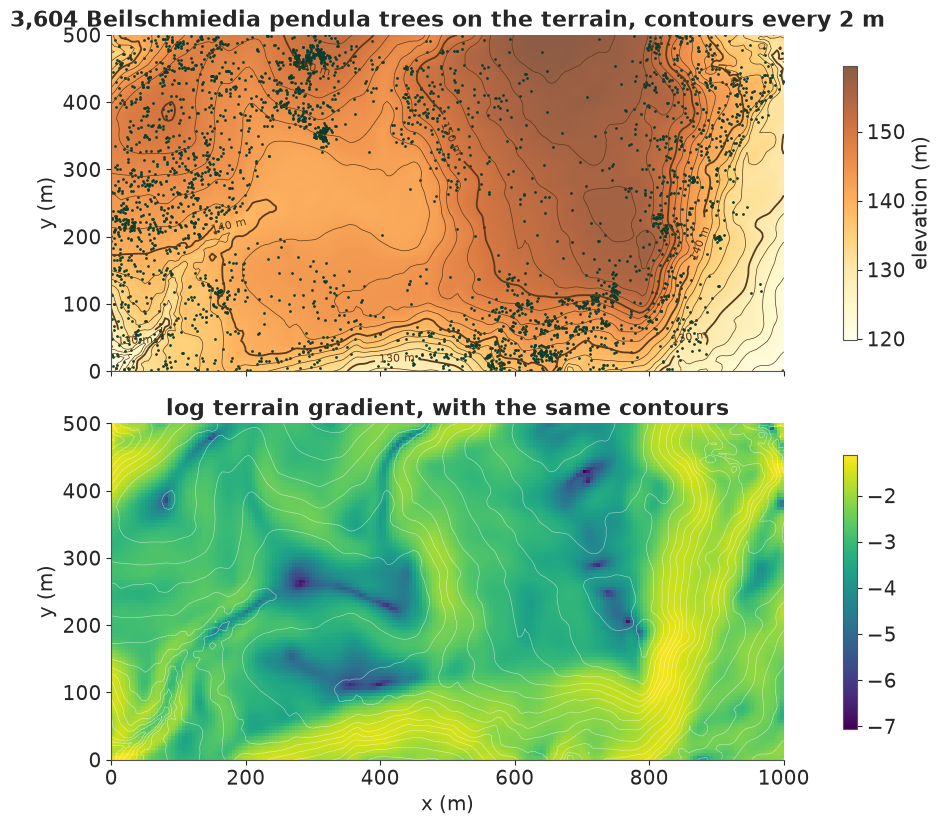

Trees per hectare, by quarter of the plot:
                 elevation  log gradient
lowest quarter        60.6          20.4
second                68.3          78.2
third                108.0          83.2
highest quarter       51.4         106.6


In [2]:
@contextlib.contextmanager
def precision(floatX):
    """Build and run a model in one precision: PyTensor's floatX and JAX's x64 must agree."""
    old = pytensor.config.floatX
    pytensor.config.floatX = floatX
    jax.config.update("jax_enable_x64", floatX == "float64")
    try:
        yield
    finally:
        pytensor.config.floatX = old
        jax.config.update("jax_enable_x64", old == "float64")


pytensor.config.floatX = "float32"
jax.config.update("jax_enable_x64", False)  # importing PyMC switches x64 on

data.describe("bei_trees")
raw = np.load(data.path("bei_trees"))
n_trees = raw["x"].size
print(f"{n_trees:,} trees; elevation grid {raw['elev'].shape}")


def lattice(cell):
    """Counts and standardised terrain on a lattice of `cell` metres."""
    nx, ny = int(1000 / cell), int(500 / cell)
    y = np.histogram2d(raw["y"], raw["x"], bins=[ny, nx], range=[[0, 500], [0, 1000]])[0]
    k = int(cell / 5)

    def to_cells(v):
        c = 0.25 * (v[:-1, :-1] + v[1:, :-1] + v[:-1, 1:] + v[1:, 1:])  # corners to 5 m centres
        return c.reshape(ny, k, nx, k).mean((1, 3))

    standard = lambda a: (a - a.mean()) / a.std()
    return y, standard(to_cells(raw["elev"])), standard(to_cells(np.log(raw["grad"]))), ny, nx


y5, elev5, grad5, _, _ = lattice(5.0)
fig, axes = plt.subplots(2, 1, figsize=(9, 8.2), sharex=True, layout="constrained")
extent = (0, 1000, 0, 500)
grid_y, grid_x = (np.linspace(0, size, n) for size, n in zip((500, 1000), raw["elev"].shape))
levels = np.arange(np.floor(raw["elev"].min() / 2) * 2, raw["elev"].max() + 2, 2)  # every 2 m

im = axes[0].imshow(raw["elev"], origin="lower", extent=extent, cmap="YlOrBr", alpha=0.75)
lines = axes[0].contour(grid_x, grid_y, raw["elev"], levels=levels, colors="#5b3a1a")
lines.set_linewidths([1.3 if level % 10 == 0 else 0.5 for level in lines.levels])  # index contours
axes[0].clabel(lines, levels=[level for level in levels if level % 10 == 0], fmt="%d m", fontsize=8)
axes[0].scatter(raw["x"], raw["y"], s=4, c="#0b3d2e", linewidths=0)
axes[0].set(title=f"{n_trees:,} Beilschmiedia pendula trees on the terrain, contours every 2 m", ylabel="y (m)",
            aspect="equal", xlim=(0, 1000), ylim=(0, 500))
fig.colorbar(im, ax=axes[0], shrink=0.8, label="elevation (m)")

im = axes[1].imshow(np.log(raw["grad"]), origin="lower", extent=extent, cmap="viridis")
axes[1].contour(grid_x, grid_y, raw["elev"], levels=levels, colors="w", linewidths=0.4, alpha=0.6)
axes[1].set(title="log terrain gradient, with the same contours", xlabel="x (m)", ylabel="y (m)")
fig.colorbar(im, ax=axes[1], shrink=0.8)
plt.show()


def trees_per_ha(terrain):
    """Mean tree density in the four quartiles of a terrain variable, on the 5 m cells."""
    quartile = pd.qcut(terrain.ravel(), 4, labels=["lowest quarter", "second", "third", "highest quarter"])
    return (pd.Series(y5.ravel()).groupby(quartile, observed=True).mean() * 400).round(1)  # 400 cells a hectare


print("Trees per hectare, by quarter of the plot:")
print(pd.DataFrame({"elevation": trees_per_ha(elev5), "log gradient": trees_per_ha(grad5)}).to_string());

Trees avoid the centre of the plot and bunch into tight clumps. The contours show what that centre
is: a flat hollow, with a western rise, a higher plateau to the east and steep edges running
between them. Density climbs steadily with gradient, from 20 to 107 trees per hectare across the
quarters of the plot. Elevation shows no steady trend, and its highest quarter holds the fewest
trees, a first hint at the brief's question. (The R documentation says 3,605
trees; the file holds 3,604.) For a homogeneous Poisson process, counts across quadrats have
variance equal to their mean, whatever the quadrat size. Here:

In [3]:
def vmr(counts, block):
    """Variance-to-mean ratio of counts summed over blocks of `block` x `block` cells."""
    ny, nx = counts.shape
    b = counts.reshape(ny // block, block, nx // block, block).sum((1, 3))
    return b.var() / b.mean()


print(pd.Series({f"{5 * b} m": vmr(y5, b) for b in (1, 2, 4, 10, 20)}, name="variance / mean of counts").round(1).to_string())

5 m       2.1
10 m      4.2
20 m      9.0
50 m     24.1
100 m    51.7


The ratio climbs from 2 at 5 m to 52 at 100 m: clustering at every scale, far more than terrain
covariates alone can produce (a covariate-only Poisson fit gives about 1 at 5 m and 10-14 at 100
m). This table becomes our predictive check.

**The model.** Counts in each cell $i$ of area $a$ are Poisson with

$$\log \lambda_i = \alpha + \big(b_e + g_e(s_i)\big)\,\text{elev}_i + \big(b_g + g_g(s_i)\big)\,\text{grad}_i
+ f_{\text{broad}}(s_i) + f_{\text{fine}}(s_i) + \log a .$$

- $g_e, g_g$: **spatially varying effects** of elevation and of log gradient (Matern 3/2, sharing a lengthscale).
- $f_{\text{broad}}$: large-scale variation the terrain does not explain (Matern 3/2).
- $f_{\text{fine}}$: clumps from local seed dispersal. It uses a **Matern 1/2**, which is much
  rougher, with 100 x 200 modes, reaching about 80% of the lattice's Nyquist frequency.

Each field is a Hilbert-space GP (as in E05), written non-centred. On a grid the basis factorises, so a field is

$$f = \Phi_y \,\big(\sqrt{S} \circ z\big)\, \Phi_x^\top,$$

two dense matrix products per field per gradient. This is the operation a GPU likes best.

Two fixes came from earlier drafts. The fine field first used a Matern 3/2 with 64 x 128 modes,
and its lengthscale came out near 6 m, against a 20 m prior and below what those modes can
resolve. The rougher kernel with more modes improved the fit, though the lengthscale, about 7 m,
remains close to the 5 m resolution. The basis realises about 75% of the nominal variance of such
a field, so `s_fine` is a nominal scale and the realised sd is about 0.95.

The smooth fields first used a box only 1.25 times the plot's size, and the boundary pulled their
variance to about 40% at the north and south edges: they were not stationary fields. They now use
a box of half-width 800 m, with modes to match, which is why the count reaches 24,810.

**Priors.** Field sds are **LogNormal rather than half-normal**. The reason is sampling, not
ecology, and section 6 shows why it matters. A consequence to remember: these priors rule out
exactly zero variation.

In [4]:
def basis(n, cell, half_width, m):
    """Laplacian eigenfunctions on [-L, L] at `n` cell centres, and their frequencies."""
    centres = (np.arange(n) + 0.5) * cell
    x = centres - centres.mean()
    w = np.pi * np.arange(1, m + 1) / (2 * half_width)
    return np.sqrt(1 / half_width) * np.sin(w[None, :] * (x[:, None] + half_width)), w


def matern_sqrt_density(w2, ell, nu):
    """Square root of the 2-D Matern spectral density, nu = 1/2 or 3/2."""
    constant = {0.5: 2 * np.pi / ell, 1.5: 6 * np.pi * 3**1.5 / ell**3}[nu]
    return pt.sqrt(constant) * ((2 * nu) / ell**2 + w2) ** (-(nu + 1) / 2)


def make_model(cell=CELL, m_fine=M_FINE, m_smooth=M_SMOOTH):
    y, elev, grad, ny, nx = lattice(cell)
    fx = pytensor.config.floatX
    Ly, Lx = 1.25 * 250.0, 1.25 * 500.0
    Py, wy = basis(ny, cell, Ly, m_fine[0])
    Px, wx = basis(nx, cell, Lx, m_fine[1])
    Qy, vy = basis(ny, cell, L_SMOOTH, m_smooth[0])
    Qx, vx = basis(nx, cell, L_SMOOTH, m_smooth[1])
    w2 = (wy[:, None] ** 2 + wx[None, :] ** 2).astype(fx)
    v2 = (vy[:, None] ** 2 + vx[None, :] ** 2).astype(fx)
    Py, Px, Qy, Qx = Py.astype(fx), Px.astype(fx), Qy.astype(fx), Qx.astype(fx)
    elev, grad = elev.astype(fx), grad.astype(fx)
    log_area = np.log(cell**2 / 1e4)  # intensity is per hectare

    with pm.Model() as model:
        alpha = pm.Normal("alpha", np.log(30.0), 1.0)
        b_elev = pm.Normal("b_elev", 0.0, 1.0)
        b_grad = pm.Normal("b_grad", 0.0, 1.0)
        s_broad = pm.LogNormal("s_broad", np.log(0.7), 0.5)
        ell_broad = pm.LogNormal("ell_broad", np.log(120.0), 0.4)
        s_fine = pm.LogNormal("s_fine", np.log(0.7), 0.5)
        ell_fine = pm.LogNormal("ell_fine", np.log(20.0), 0.6)
        s_slope_elev = pm.LogNormal("s_slope_elev", np.log(0.5), 0.5)
        s_slope_grad = pm.LogNormal("s_slope_grad", np.log(0.5), 0.5)
        ell_slope = pm.LogNormal("ell_slope", np.log(200.0), 0.4)
        z_broad = pm.Normal("z_broad", 0.0, 1.0, shape=m_smooth)
        z_fine = pm.Normal("z_fine", 0.0, 1.0, shape=m_fine)
        z_elev = pm.Normal("z_elev", 0.0, 1.0, shape=m_smooth)
        z_grad = pm.Normal("z_grad", 0.0, 1.0, shape=m_smooth)

        smooth = lambda z, sd: Qy @ (sd * z) @ Qx.T
        broad = smooth(z_broad, s_broad * matern_sqrt_density(v2, ell_broad, 1.5))
        fine = Py @ (s_fine * matern_sqrt_density(w2, ell_fine, 0.5) * z_fine) @ Px.T
        sd_slope = matern_sqrt_density(v2, ell_slope, 1.5)
        slope_elev = b_elev + smooth(z_elev, s_slope_elev * sd_slope)
        slope_grad = b_grad + smooth(z_grad, s_slope_grad * sd_slope)
        habitat = alpha + slope_elev * elev + slope_grad * grad + broad
        eta = habitat + fine + log_area
        pm.Poisson("y", pt.exp(eta), observed=y)
    outputs = {"eta": eta, "habitat": habitat, "slope_elev": slope_elev, "slope_grad": slope_grad}
    return model, y, outputs


model, y, outputs = make_model()
print(f"{y.size:,} cells, {sum(v.size for v in model.initial_point().values()):,} parameters")

20,000 cells, 24,810 parameters


A prior predictive check. The total should cover the observed 3,604 without being dominated by absurd forests.

In [5]:
HYPER = ["alpha", "b_elev", "b_grad", "s_broad", "ell_broad", "s_fine", "ell_fine",
         "s_slope_elev", "s_slope_grad", "ell_slope"]
with model:
    prior = pm.sample_prior_predictive(200, var_names=["y"], random_seed=RANDOM_SEED)
prior_y = prior.prior_predictive["y"].values[0]
total = prior_y.sum((1, 2))
print("prior predictive trees in the plot, 5/50/95%:", np.percentile(total, [5, 50, 95]).round(-2))
print("cells with count above 1,000 in", f"{(prior_y.max((1, 2)) > 1000).mean():.0%} of prior draws")
del prior, prior_y

prior predictive trees in the plot, 5/50/95%: [   900.   9700. 217400.]
cells with count above 1,000 in 14% of prior draws


The prior is generous, with a 90% interval of about 900 to 220,000 trees, and 14% of draws put
more than 1,000 trees in a 25 square metre cell at least once. That upper tail is too wide to be
realistic, but 20,000 cells of data will overwhelm it, and the observed total sits comfortably
inside.

## 2. The baseline: NUTS on the CPU

Every comparison needs a fair opponent, and a speed-up is only as honest as its baseline. nutpie
is a very good NUTS sampler, so we run it in double precision on the same model, and configure it
well. First, one BLAS thread per chain, set at the very top of the notebook: left alone, each
chain's matrix products compete on a 30-thread pool, and the first version of this notebook ran
about 2-3x slower for that reason alone. Second, more chains than the default: 8, one per physical
core, sharing 4,000 draws. Third, for memory: nutpie stores every free variable, because
`var_names` only filters derived ones, so the trace goes to a temporary zarr store on disk, a GB or so, and only the hyperparameters come back.

In [6]:
with precision("float64"):
    model64, _, _ = make_model()
    t0 = time.perf_counter()
    # nutpie stores every free variable (var_names only filters derived ones): the trace goes to disk and only
    # the hyperparameters come back into memory
    with tempfile.TemporaryDirectory() as trace_dir:
        idata_nuts = nutpie.sample(nutpie.compile_pymc_model(model64, var_names=HYPER), draws=NUTS_DRAWS, tune=400,
                                   chains=NUTS_CHAINS, cores=NUTS_CHAINS, seed=RANDOM_SEED, progress_bar=False,
                                   save_warmup=False, store_mass_matrix=False,
                                   zarr_store=nutpie.zarr_store.LocalStore(trace_dir))
        nuts_wall = time.perf_counter() - t0
        draws_nuts = np.stack([idata_nuts.posterior[n].values for n in HYPER], -1)
        n_steps = float(idata_nuts.sample_stats["n_steps"].mean())
        diverging = int(idata_nuts.sample_stats["diverging"].sum())
    del model64, idata_nuts
tuning = 400

ds_nuts = xr.Dataset({n: (("chain", "draw"), draws_nuts[..., i]) for i, n in enumerate(HYPER)})
rhat_nuts, ess_nuts = az.rhat(ds_nuts), az.ess(ds_nuts)
summary_nuts = pd.DataFrame({"mean": draws_nuts.mean((0, 1)), "sd": draws_nuts.std((0, 1)),
                             "r_hat": [float(rhat_nuts[n]) for n in HYPER],
                             "ess": [float(ess_nuts[n]) for n in HYPER]}, index=HYPER)
print(f"nutpie on the CPU: {NUTS_CHAINS} chains, {nuts_wall:.0f} s, {diverging} divergences, {n_steps:.0f} leapfrog steps per draw, {tuning} tuning steps")
print(summary_nuts.round(3).to_string())

nutpie on the CPU: 8 chains, 121 s, 0 divergences, 63 leapfrog steps per draw, 400 tuning steps
                 mean      sd  r_hat       ess
alpha           3.412   0.375  1.031   231.645
b_elev          0.613   0.342  1.037   268.006
b_grad          0.534   0.250  1.028   344.495
s_broad         1.091   0.190  1.036   320.751
ell_broad     112.076  26.022  1.055   136.325
s_fine          1.103   0.036  1.005  1460.784
ell_fine        7.014   0.788  1.014   770.687
s_slope_elev    0.779   0.243  1.034   292.868
s_slope_grad    0.554   0.170  1.009   654.378
ell_slope     164.480  47.197  1.022   442.345


It works: about 120 s, no divergences, and only about 63 leapfrog steps per draw, because the
non-centred posterior is well conditioned. The weakness is effective sample size. The worst
parameters reach an ESS of only about 140 with r_hat 1.05, which is the usual trouble with the
hyperparameters of a latent Gaussian model. Run once outside this notebook, 14 chains took 139 s
with a worst ESS of 187 and r_hat 1.10: about 20% more ESS per second, so the choice of 8 is not
hiding much.

## 3. Where the time goes

Now JAX starts. `get_jaxified_logp` turns the PyMC model into a JAX function, so the model stays in PyMC. Beware of its
flag: `negative_logp=True`, the default, returns **+logp**, and `False` flips the sign. We check against PyMC, on a
small lattice because `compile_logp` is memory-hungry at full size.

We time `value_and_grad` under `vmap`, the unit of all gradient-based sampling. `block_until_ready` matters: JAX
dispatches work asynchronously, and without it you time the queueing rather than the arithmetic.

In [7]:
import blackjax  # CUDA starts here, not before
import optax
from blackjax.adaptation.base import get_filter_adapt_info_fn

key = jax.random.key(RANDOM_SEED)
if (jax.default_backend() == "gpu") != HAS_GPU:
    raise RuntimeError(f"expected GPU={HAS_GPU} but JAX chose {jax.default_backend()}: if your GPU is not usable, "
                       "run with JAX_PLATFORMS=cpu")
print("JAX backend:", jax.default_backend(), jax.devices())


def jaxify(m):
    """One flat parameter vector -> log density, plus the unravel function."""
    logp = get_jaxified_logp(m)  # NB: the default negative_logp=True returns +logp
    start = m.initial_point()
    names = [v.name for v in m.value_vars]
    q0, unravel = ravel_pytree([jnp.asarray(start[n]) for n in names])
    return (lambda q: logp(unravel(q))), q0, unravel, names


logdensity, q0, unravel, names = jaxify(model)
print("value variables:", names[:10], "...")
small, _, _ = make_model(25.0, (20, 40), (16, 16))  # the check on a small lattice: compile_logp is heavy
f_small, q_small, _, _ = jaxify(small)
print(f"25 m lattice: PyMC logp {small.compile_logp()(small.initial_point()):.2f}, JAX logp {float(f_small(q_small)):.2f}")
del small, f_small, q_small
NH = len(HYPER)
value_is_log = np.array([n.endswith("_log__") for n in names[:NH]])


def timed(fn, *args, repeat=5):
    """(compile seconds, best-of-`repeat` run seconds). block_until_ready defeats async dispatch."""
    t0 = time.perf_counter()
    jax.block_until_ready(fn(*args))
    compile_s = time.perf_counter() - t0
    runs = []
    for _ in range(repeat):
        t0 = time.perf_counter()
        jax.block_until_ready(fn(*args))
        runs.append(time.perf_counter() - t0)
    return compile_s, min(runs)


def batch_gradient(f, q, chains, device):
    Q = jax.device_put(q + 0.1 * jnp.asarray(rng.normal(size=(chains, q.size)), q.dtype), device)
    result = timed(jax.jit(jax.vmap(jax.value_and_grad(f))), Q)
    jax.clear_caches()  # every chain count is a new compiled program, kept alive otherwise
    return result


cpu = jax.devices("cpu")[0]
gpu = jax.devices("gpu")[0] if HAS_GPU else None
chain_grid = sorted({1, 8, 32, 128, 512, CHAINS}) if HAS_GPU else sorted({1, 8, CHAINS})
rows = []
for chains in chain_grid:
    compile_cpu, cpu_s = batch_gradient(logdensity, q0, chains, cpu) if chains <= 128 else (np.nan, np.nan)
    row = {"chains": chains, "CPU float32": cpu_s * 1e3, "compile CPU s": compile_cpu}
    if HAS_GPU:
        compile_gpu, gpu_s = batch_gradient(logdensity, q0, chains, gpu)
        row |= {"GPU float32": gpu_s * 1e3, "compile GPU s": compile_gpu}
    rows.append(row)
timing = pd.DataFrame(rows).set_index("chains")

if HAS_GPU:  # the same model in double precision
    with precision("float64"):
        model64, _, _ = make_model()
        f64, q64, _, _ = jaxify(model64)
        timing["GPU float64"] = [batch_gradient(f64, q64, c, gpu)[1] * 1e3 for c in chain_grid]
    del model64, f64, q64
    timing["GPU speed-up"] = timing["CPU float32"] / timing["GPU float32"]
    timing["float32 speed-up on GPU"] = timing["GPU float64"] / timing["GPU float32"]
print(timing.round(2).to_string())

JAX backend: gpu [CudaDevice(id=0)]


value variables: ['alpha', 'b_elev', 'b_grad', 's_broad_log__', 'ell_broad_log__', 's_fine_log__', 'ell_fine_log__', 's_slope_elev_log__', 's_slope_grad_log__', 'ell_slope_log__'] ...


25 m lattice: PyMC logp -6321.62, JAX logp -6321.62


        CPU float32  compile CPU s  GPU float32  compile GPU s  GPU float64  GPU speed-up  float32 speed-up on GPU
chains                                                                                                            
1              0.71           0.39         0.13           1.88         0.34          5.41                     2.59
8              2.25           0.39         0.18           1.92         1.13         12.71                     6.40
32             5.62           0.42         0.34           2.19         3.95         16.72                    11.75
128           44.73           0.46         0.85           2.00        14.34         52.80                    16.93
512             NaN            NaN         2.95           2.13        50.50           NaN                    17.11


Read the table in three directions.

**Down the columns: chains.** GPU cost grows slowly at first. 128 chains cost about 6.5 times what
one chain costs, not 128 times. The GPU's advantage grows from about 5-6x with one chain to more
than **50x** with 128. The CPU, with a fixed number of cores, falls behind: from 32 to 128 chains
its time rises six- to sevenfold, not fourfold, which suggests the work no longer fits the cache.

**Across: precision.** This is the surprise, and it is specific to consumer cards. The
double-precision hardware on this GPU is a small fraction of its single-precision hardware, so
**float32 is about 17x faster at 128 chains**. On this card float64 alone would throw away most of
the GPU's gain. Data-centre GPUs do not have this penalty.

**Compile time** goes the other way: about 2 s on the GPU against 0.4 s on the CPU. That is
negligible here, but it would dominate a workflow that recompiles for thousands of small fits.

Next, what happens as the problem shrinks?

 cell m  cells  parameters  chains  cpu ms  gpu ms  speed-up
   25.0    800        1578       1    0.07    0.11      0.61
   25.0    800        1578     128    2.19    0.14     15.10
   20.0   1250        2460       1    0.09    0.12      0.79
   20.0   1250        2460     128    2.40    0.19     12.98
   10.0   5000        7710       1    0.21    0.12      1.72
   10.0   5000        7710     128    7.19    0.33     21.52
    5.0  20000       24810       1    0.74    0.13      5.79
    5.0  20000       24810     128   45.99    0.85     54.09


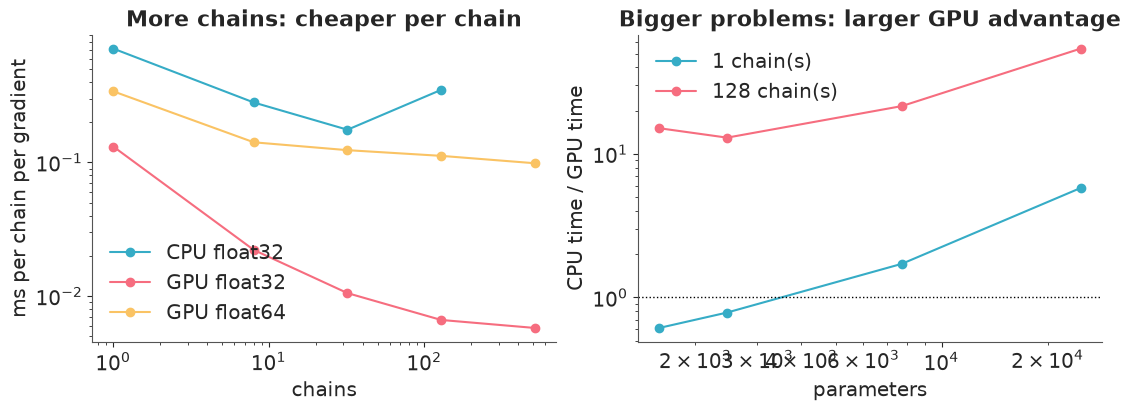

In [8]:
sizes = []
if HAS_GPU:
    for cell, mf, ms in ((25.0, (20, 40), (16, 16)), (20.0, (25, 50), (20, 20)), (10.0, (50, 100), (30, 30)), (5.0, M_FINE, M_SMOOTH)):
        m_, y_, _ = make_model(cell, mf, ms)
        f_, q_, _, _ = jaxify(m_)
        for chains in (1, 128):
            sizes.append({"cell m": cell, "cells": y_.size, "parameters": q_.size, "chains": chains,
                          "cpu ms": batch_gradient(f_, q_, chains, cpu)[1] * 1e3,
                          "gpu ms": batch_gradient(f_, q_, chains, gpu)[1] * 1e3})
        del m_, f_, q_
    sizes = pd.DataFrame(sizes)
    sizes["speed-up"] = sizes["cpu ms"] / sizes["gpu ms"]
    print(sizes.round(2).to_string(index=False))

fig, axes = plt.subplots(1, 2 if HAS_GPU else 1, figsize=(11 if HAS_GPU else 5.5, 4), layout="constrained", squeeze=False)
axes = axes[0]
per_chain = timing.filter(regex="(CPU|GPU) float").div(timing.index, axis=0).dropna(how="all")
for label in per_chain:
    axes[0].plot(per_chain.index, per_chain[label], "o-", label=label)
axes[0].set(xscale="log", yscale="log", xlabel="chains", ylabel="ms per chain per gradient", title="More chains: cheaper per chain")
axes[0].legend(loc="lower left")
if HAS_GPU:
    for chains, group in sizes.groupby("chains"):
        axes[1].plot(group["parameters"], group["speed-up"], "o-", label=f"{chains} chain(s)")
    axes[1].axhline(1, color="k", lw=1, ls=":")
    axes[1].set(xscale="log", yscale="log", xlabel="parameters", ylabel="CPU time / GPU time", title="Bigger problems: larger GPU advantage")
    axes[1].legend();

The left panel shows the cost per chain falling with more chains on the GPU, and the right panel
gives the decision rule. **The GPU does not help a small problem with one chain** (0.5-0.8x the
CPU's speed across runs at 1,578 parameters), probably because every call pays a fixed cost to
reach the card. It wins everywhere with 128 chains, and increasingly so with size. So a GPU is not
simply faster. It is faster at large batches of large array operations.

## 4. ChEES-HMC

HMC has two settings, step size and trajectory length. NUTS picks the length separately for each chain at each
iteration. **ChEES** (Hoffman, Radul & Sountsov, 2021) instead picks one length for all chains during warmup, by
maximising the *Change in the Estimator of the Expected Square*: how much a trajectory moves each chain's squared
distance from the ensemble mean. Every chain then runs the same number of leapfrog steps, jittered
from one iteration to the next, so nothing has to wait for anything else. The `L` printed below is
the maximum: each iteration draws a count that averages about L/2.

All chains start from dispersed points, so that r_hat can detect problems. With the default settings, this happens:

In [9]:
key, init_key = jax.random.split(key)
spread = jnp.concatenate([jnp.full(NH, 0.3), jnp.ones(q0.size - NH)]).astype(q0.dtype)
cold_start = q0 + spread * jax.random.normal(init_key, (CHAINS, q0.size), q0.dtype)


def summarise(draws):
    """Posterior summary of hyperparameters, draws of shape (chain, draw, NH) on the value scale."""
    d = np.asarray(draws, float).copy()
    d[..., value_is_log] = np.exp(d[..., value_is_log])
    ds = xr.Dataset({n: (("chain", "draw"), d[..., i]) for i, n in enumerate(HYPER)})
    rhat, ess = az.rhat(ds), az.ess(ds)
    return pd.DataFrame({"mean": d.mean((0, 1)), "sd": d.std((0, 1)),
                         "r_hat": [float(rhat[n]) for n in HYPER],
                         "ess": [float(ess[n]) for n in HYPER]}, index=HYPER)


def sample(step, state, k, snaps, keep, thin):
    """Run the vectorised kernel; every `thin` steps keep hyperparameters, every `keep * thin` all of q."""
    def one(s, ki):
        s, info = jax.vmap(step)(jax.random.split(ki, CHAINS), s)
        steps = jnp.mean(getattr(info, "num_integration_steps", jnp.ones(())))
        return s, (info.acceptance_rate, info.is_divergent, steps)

    def keep_block(s, ki):
        s, (acc, div, steps) = jax.lax.scan(one, s, jax.random.split(ki, thin))
        return s, (s.position[:, :NH], acc.mean(), div.sum(), steps.sum())

    def snap_block(s, ki):
        s, out = jax.lax.scan(keep_block, s, jax.random.split(ki, keep))
        return s, (s.position, out)

    state, (positions, (kept, acc, div, steps)) = jax.lax.scan(snap_block, state, jax.random.split(k, snaps))
    kept = np.asarray(kept).reshape(snaps * keep, CHAINS, NH).transpose(1, 0, 2)
    return state, positions, kept, {"acceptance": float(acc.mean()), "divergences": int(div.sum()),
                                    "gradients per chain": float(steps.sum())}


def warm_chees(k, start, steps, **options):
    warmup = blackjax.chees_adaptation(logdensity, CHAINS, adaptation_info_fn=get_filter_adapt_info_fn(), **options)
    (state, params), _ = warmup.run(k, start, step_size=0.01, optim=optax.adam(0.05), num_steps=steps)
    return jax.block_until_ready(state), params


def run_chees(k, start, **options):
    """Plain ChEES: one warmup, then sampling."""
    k1, k2 = jax.random.split(k)
    t0 = time.perf_counter()
    state, params = warm_chees(k1, start, WARMUP, **options)
    t1 = time.perf_counter()
    state, positions, kept, stats = sample(blackjax.dynamic_hmc(logdensity, **params).step, state, k2, SNAPS, KEEP, 1)
    jax.block_until_ready(positions)
    t2 = time.perf_counter()
    stats |= {"step size": float(params["step_size"]), "L": float(params["integration_steps_params"][0]),
              "warmup s": t1 - t0, "sampling s": t2 - t1}
    return state, params, positions, kept, stats


key, k = jax.random.split(key)
_, _, positions, kept_id, stats_id = run_chees(k, cold_start)
del positions
summary_id = summarise(kept_id)
print({a: round(b, 4) for a, b in stats_id.items()})
print(summary_id.round(3).to_string())

{'acceptance': 0.8894, 'divergences': 1, 'gradients per chain': 23073.0, 'step size': 0.0101, 'L': 153.2255, 'warmup s': 27.7556, 'sampling s': 21.5041}
                 mean      sd  r_hat       ess
alpha           3.404   0.368  1.013  7700.653
b_elev          0.626   0.345  1.014  8493.493
b_grad          0.514   0.245  1.012  9158.615
s_broad         1.100   0.200  1.013  8208.039
ell_broad     114.739  28.097  1.063  1513.397
s_fine          1.104   0.036  1.018  5770.107
ell_fine        7.065   0.815  1.047  2187.840
s_slope_elev    0.785   0.243  1.041  2391.765
s_slope_grad    0.559   0.170  1.033  2735.062
ell_slope     165.009  45.175  1.041  2524.059


**The first failure is a quiet one.** Acceptance is a healthy 0.87 or so, and divergences swing
from none to a few hundred between identical runs. But the largest r_hat is well above the 1.01 we
want, and the worst ESS is roughly six to twenty times lower than after the fix below. Earlier versions of this
model did worse from the same settings: r_hat 1.24, 900 divergences, and one chain stranded at
half the others' `s_fine`. With the default identity metric nothing corrects for the scale
differences between parameters, so the step size stays small, near 0.010.

`mass_matrix_estimation="diagonal"` estimates a diagonal metric from the ensemble and adds a
trajectory-length floor. The floor needs a d x d covariance accumulator: 2.3 GB of GPU memory in
float32 at this size, and 4.6 GB in float64.

**The second failure took longer to find.** With the metric on, an early complete run of this
notebook gave a maximum trajectory of 728 steps, 452 divergences and an expected total of 4,428
trees, against 3,604 observed. Other seeds were fine. Across runs the length went 181, 246, 265,
661, 728, and high values went with bad results. A chain that gets stuck early has a log density
hundreds of robust sds from the rest, and the floor scales with the spread of the ensemble, so
**one straggler can inflate the trajectory for all the chains**. In a test of four seeds, two had
stragglers after 300 warmup steps, with lengths of 885 and 978, against 473 and 545 for the
others.

The fix is to warm up in two stages: flag chains far from the ensemble, restart them from copies
of healthy ones, then run a second, fresh warmup. All four seeds then settled at 105-115 steps.
The restart does part of this itself, because blackjax starts its adaptation again. Copies
separate immediately, because their momenta differ, and this happens **only during warmup**, so
the target distribution is untouched. There is a real risk, though: culling would hide a true
minor mode. In the seeds that had stragglers, the flagged chains had far lower log density than
the rest, so they were stuck rather than exploring. Check that before you copy this recipe.

stage 1 (300 steps): step size 0.0213, L = 606, 0 straggler(s); worst log density z = 2.7; stragglers' log density [], median -42347


stage 2 (700 steps): step size 0.0262, L = 180, 0 straggler(s) culled


{'acceptance': 0.8983, 'divergences': 2, 'gradients per chain': 27161.0, 'step size': 0.0262, 'L': 179.9161, 'warmup s': 112.9551, 'sampling s': 24.6254}
                 mean      sd  r_hat        ess
alpha           3.398   0.371  1.005  30698.661
b_elev          0.617   0.343  1.004  31183.001
b_grad          0.510   0.248  1.006  30839.353
s_broad         1.102   0.203  1.004  22690.534
ell_broad     114.256  28.052  1.009  10210.765
s_fine          1.104   0.036  1.005  16416.239
ell_fine        7.069   0.810  1.008  11046.686
s_slope_elev    0.781   0.241  1.004  17539.094
s_slope_grad    0.557   0.171  1.005  17063.921
ell_slope     165.953  45.763  1.006  14452.420


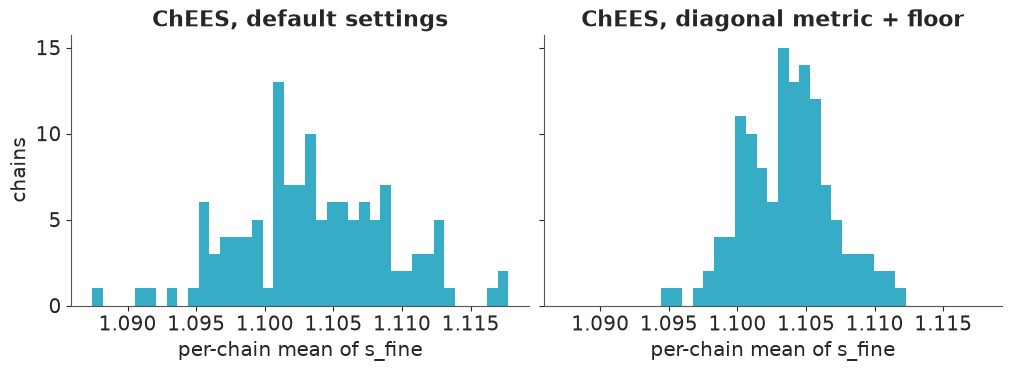

In [10]:
log_density_batch = jax.jit(jax.vmap(logdensity))


def stragglers(state, threshold=6.0):
    """Chains more than `threshold` robust sds from the ensemble in log density or any hyperparameter."""
    h = np.c_[np.asarray(log_density_batch(state.position)), np.asarray(state.position[:, :NH])]
    median = np.median(h, 0)
    z = np.abs(h - median) / (1.4826 * np.median(np.abs(h - median), 0))
    return (z > threshold).any(1), z


def cull(state, bad):
    """Warmup only: restart flagged chains from copies of healthy ones (their paths separate at once)."""
    source = np.arange(CHAINS)
    source[bad] = rng.choice(np.flatnonzero(~bad), bad.sum())
    return jax.tree.map(lambda leaf: leaf[source], state)


key, k1, k2, k3 = jax.random.split(key, 4)
options = {"mass_matrix_estimation": "diagonal"}
t0 = time.perf_counter()
state, params = warm_chees(k1, cold_start, int(0.3 * WARMUP), **options)
bad, z = stragglers(state)
print(f"stage 1 ({int(0.3 * WARMUP)} steps): step size {float(params['step_size']):.4f}, L = {float(params['integration_steps_params'][0]):.0f}, {bad.sum()} straggler(s); "
      f"worst log density z = {z[:, 0].max():.1f}; stragglers' log density {np.asarray(log_density_batch(state.position))[bad].round(0)}, "
      f"median {np.median(np.asarray(log_density_batch(state.position))):.0f}")
state = cull(state, bad)
state, params_chees = warm_chees(k2, state.position, WARMUP - int(0.3 * WARMUP), **options)
bad, z = stragglers(state)
print(f"stage 2 ({WARMUP - int(0.3 * WARMUP)} steps): step size {float(params_chees['step_size']):.4f}, L = {float(params_chees['integration_steps_params'][0]):.0f}, {bad.sum()} straggler(s) culled")
state = cull(state, bad)
t1 = time.perf_counter()
state_chees, pos_chees, kept_chees, stats_chees = sample(blackjax.dynamic_hmc(logdensity, **params_chees).step, state, k3, SNAPS, KEEP, 1)
jax.block_until_ready(pos_chees)
stats_chees |= {"step size": float(params_chees["step_size"]), "L": float(params_chees["integration_steps_params"][0]),
                "warmup s": t1 - t0, "sampling s": time.perf_counter() - t1}
summary_chees = summarise(kept_chees)
print({a: round(b, 4) for a, b in stats_chees.items()})
print(summary_chees.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharex=True, sharey=True, layout="constrained")
i = HYPER.index("s_fine")
means = [np.exp(kept[..., i]).mean(1) for kept in (kept_id, kept_chees)]
bins = np.linspace(min(m.min() for m in means), max(m.max() for m in means), 40)
for ax, m, title in zip(axes, means, ("ChEES, default settings", "ChEES, diagonal metric + floor")):
    ax.hist(m, bins=bins, color="C0")
    ax.set(title=title, xlabel="per-chain mean of s_fine")
axes[0].set_ylabel("chains");

This seed has no stragglers, though the check stays because you cannot know that in advance.
Notice that L still falls from 600-650 to 150-180 with nothing culled: a high early L alone is
not proof of a straggler, and the second warmup does that work. The run has a handful of
divergences, r_hat at most about 1.01, and a worst ESS of 8,000-10,000: sixty to seventy-five times nutpie's, in about 130-140 s. Warmup takes about 85% of that. In the figure, the default run's chains are spread
more widely than the fixed run's, which is what a high r_hat looks like.

## 5. Why not just run NUTS on the GPU?

The usual explanation is that NUTS trees differ between chains, so under `vmap` every chain waits for the largest
tree. Let us measure that, on the same model with the same metric and step size.

In [11]:
steps_nuts = 30 if HAS_GPU else 10
nuts = blackjax.nuts(logdensity, step_size=params_chees["step_size"], inverse_mass_matrix=params_chees["inverse_mass_matrix"])
nuts_state = jax.vmap(nuts.init)(state_chees.position)


def nuts_iteration(s, ki):
    s, info = jax.vmap(nuts.step)(jax.random.split(ki, CHAINS), s)
    return s, info.num_integration_steps


nuts_run = jax.jit(lambda k: jax.lax.scan(nuts_iteration, nuts_state, jax.random.split(k, steps_nuts))[1])
key, k = jax.random.split(key)
tree_sizes = np.asarray(jax.block_until_ready(nuts_run(k)))   # compiles
key, k = jax.random.split(key)
t0 = time.perf_counter()
tree_sizes = np.asarray(jax.block_until_ready(nuts_run(k)))
nuts_s = time.perf_counter() - t0

chees_step = blackjax.dynamic_hmc(logdensity, **params_chees).step


def chees_iteration(s, ki):
    s, info = jax.vmap(chees_step)(jax.random.split(ki, CHAINS), s)
    return s, (info.num_integration_steps, s.position.mean())  # the sizes alone are a fixed sequence: without
    #                                                             the position XLA deletes the whole sampler


chees_run = jax.jit(lambda k: jax.lax.scan(chees_iteration, state_chees, jax.random.split(k, steps_nuts))[1])
key, k = jax.random.split(key)
jax.block_until_ready(chees_run(k))
key, k = jax.random.split(key)
t0 = time.perf_counter()
chees_sizes = np.asarray(jax.block_until_ready(chees_run(k))[0])
chees_s = time.perf_counter() - t0
bare = timing.loc[CHAINS, "GPU float32" if HAS_GPU else "CPU float32"]
print(f"vectorised NUTS: {tree_sizes.mean():.0f} leapfrog steps per iteration, largest tree per iteration {tree_sizes.max(1).mean():.0f}; "
      f"tree sizes seen {np.unique(tree_sizes)}; {tree_sizes.sum() / (tree_sizes.max(1).sum() * CHAINS):.0%} of the work needed")
print(pd.DataFrame({"gradients per iteration": [tree_sizes.max(1).mean(), chees_sizes.max(1).mean()],
                    "ms per gradient": [1e3 * nuts_s / tree_sizes.max(1).sum(), 1e3 * chees_s / chees_sizes.max(1).sum()]},
                   index=["NUTS", "ChEES"]).round(2).to_string())
print(f"a bare batched gradient costs {bare:.2f} ms")
del nuts_run, chees_run
jax.clear_caches()

vectorised NUTS: 127 leapfrog steps per iteration, largest tree per iteration 127; tree sizes seen [ 38 127]; 100% of the work needed
       gradients per iteration  ms per gradient
NUTS                    127.00             3.59
ChEES                    92.17             0.86
a bare batched gradient costs 0.85 ms


The usual explanation **does not apply here**. Trees here have 127 steps, with the odd exception
in some runs, so almost no work is wasted: this posterior is so homogeneous that the chains stop
at the same depth. On a model with more varied geometry the trees would differ, and that cost
would appear.

The cost that does appear is **bookkeeping**. Each NUTS gradient costs about 3.6 ms against 0.86 ms for ChEES, which
matches a bare batched gradient. Building trees under `vmap` means saving and masking states, and `while_loop`s that
XLA cannot flatten. ChEES has almost no overhead at all: its time *is* its gradients. Note the benchmark's own trap:
`num_integration_steps` is a fixed sequence, so timing it alone lets XLA delete the entire sampler as dead code. We
return a statistic of the positions to keep the work alive.

## 6. MEADS

**MEADS** (Hoffman & Sountsov, 2022) goes further and removes the trajectory altogether. It uses
*generalised* HMC: a single leapfrog step per iteration, with momentum kept and only partly
refreshed. During warmup the chains are split into folds. Each fold takes its step size and metric
from a neighbouring fold and its damping from its own positions, one fold is frozen at each step,
and the chains are reshuffled. Sampling then uses one fixed kernel with averaged settings. There
is no trajectory length to tune, and no warmup optimiser.

Start it from the same dispersed points:

In [12]:
def run_meads(k, start, multiplier):
    k1, k2 = jax.random.split(k)
    t0 = time.perf_counter()
    warmup = blackjax.meads_adaptation(logdensity, CHAINS, num_folds=4, step_size_multiplier=multiplier,
                                       adaptation_info_fn=get_filter_adapt_info_fn())
    (state, params), _ = warmup.run(k1, start, MEADS_WARMUP)
    jax.block_until_ready(state)
    t1 = time.perf_counter()
    state, positions, kept, stats = sample(blackjax.ghmc(logdensity, **params).step, state, k2, SNAPS, MEADS_KEEP, MEADS_THIN)
    jax.block_until_ready(positions)
    t2 = time.perf_counter()
    scale = np.asarray(params["momentum_inverse_scale"])
    stats |= {"step size": float(params["step_size"]), "alpha": float(params["alpha"]), "delta": float(params["delta"]),
              "largest scale": float(scale.max()), "warmup s": t1 - t0, "sampling s": t2 - t1}
    return state, params, positions, kept, stats


key, k = jax.random.split(key)
_, _, positions, kept_cold, stats_cold = run_meads(k, cold_start, 0.25)
del positions
print("MEADS, cold start:", {a: round(b, 5) for a, b in stats_cold.items()})
print(summarise(kept_cold)[["r_hat", "ess"]].round(2).T.to_string())

MEADS, cold start: {'acceptance': 0.82452, 'divergences': 0, 'gradients per chain': 39000.0, 'step size': 0.0, 'alpha': 0.0001, 'delta': 5e-05, 'largest scale': 15.30351, 'warmup s': 39.11603, 'sampling s': 46.62223}
        alpha  b_elev  b_grad  s_broad  ell_broad  s_fine  ell_fine  s_slope_elev  s_slope_grad  ell_slope
r_hat  118.23   82.51   43.56    29.89     186.84   15.26     41.89         32.91         26.95      31.35
ess    130.02  130.11  130.07   130.15     130.01  130.58    130.08        130.13        130.20     130.15


**A clean-looking catastrophe.** Acceptance is near 0.8 and there are almost no divergences, yet
r_hat runs from about 10 into the hundreds or beyond, and ESS equals the number of chains. The
step size has collapsed to zero, so the chains are frozen, and a frozen chain *accepts* its
proposals. MEADS sets the step size from an estimate of the largest eigenvalue of the scaled
gradients, and from a dispersed start one chain with a huge gradient can dominate that estimate.

A short Adam run does not help. It overshoots the typical set to a mode near -23,000, where real
draws then sat near -37,700, and gradients in that funnel are larger still. What helps is a start
*in* the typical set, which ChEES already gave us.

Three more settings were needed, and getting to them taught something:

- **`step_size_multiplier=0.25`.** The default of 0.5 gave acceptance of only 0.15-0.4, and r_hat
  from 1.2 to 2.

- **Enough chains in a fold.** On the 20 m lattice, 32 chains (8 per fold) collapsed on one seed
  of three; 64 chains (16 per fold) held on all three. This is why the CPU configuration uses 64.

- **The priors.** With half-normal and then Gamma priors on field sds, MEADS blew up: a log-sd ran
  to about -44 million. We first blamed float32, since GHMC's one-step Metropolis test compares
  tiny energy differences. That was wrong: the blow-up happened in float64 too. (float32 did go
  with far more divergences, 1,266 against 3 in one comparison, but rounding of this size cannot
  itself cause a divergence, and we did not find the mechanism.) Our best reading is this: those
  priors have a **linear tail in log sd**, with a nearly constant gradient, so nothing limits the
  step in that direction. A chain wanders down the tail, the fold's scale estimate grows, and that
  makes the next step bigger. A LogNormal prior has a *quadratic* tail, whose gradient grows with
  distance. With it, MEADS converged on all three seeds tried at 128 chains.

In [13]:
key, k = jax.random.split(key)
_, params_meads, pos_meads, kept_meads, stats_meads = run_meads(k, state_chees.position, 0.25)
summary_meads = summarise(kept_meads)
print("MEADS, started from ChEES:", {a: round(b, 5) for a, b in stats_meads.items()})
print(summary_meads.round(3).to_string())

MEADS, started from ChEES: {'acceptance': 0.97654, 'divergences': 0, 'gradients per chain': 39000.0, 'step size': 0.016, 'alpha': 0.00617, 'delta': 0.00309, 'largest scale': 1.47273, 'warmup s': 31.96501, 'sampling s': 46.14637}
                 mean      sd  r_hat        ess
alpha           3.398   0.365  1.006  19962.562
b_elev          0.617   0.338  1.006  22825.406
b_grad          0.511   0.248  1.005  19914.657
s_broad         1.098   0.201  1.004  21491.688
ell_broad     113.541  27.718  1.011  10166.427
s_fine          1.102   0.037  1.007  14622.563
ell_fine        7.065   0.814  1.008  11803.045
s_slope_elev    0.776   0.241  1.005  15511.039
s_slope_grad    0.554   0.167  1.004  19062.212
ell_slope     166.002  45.878  1.006  16273.271


From a clean ensemble, MEADS is excellent, though it varies between identical runs: acceptance
0.94-0.98, no divergences, r_hat at most about 1.01, worst ESS 10,000-19,000. Its step size is
0.016-0.03 and its damping small, so momentum persists for a hundred steps or more: long
trajectories, built one step at a time.

## 7. The scorecard

                                             seconds  worst ESS  worst r_hat  divergences  worst ESS per second  ESS/s vs NUTS
ChEES (GPU)                                   137.58   10210.76         1.01          2.0                 74.22          66.09
MEADS after ChEES (GPU)                       215.69   10166.43         1.01          0.0                 47.13          41.97
NUTS, nutpie (CPU)                            121.40     136.33         1.05          0.0                  1.12           1.00
ChEES (CPU, one 128-chain batch, estimated)  7264.12   10210.76         1.01          2.0                  1.41           1.25
ChEES (CPU, 32-chain batches, estimated)     3653.80   10210.76         1.01          2.0                  2.79           2.49


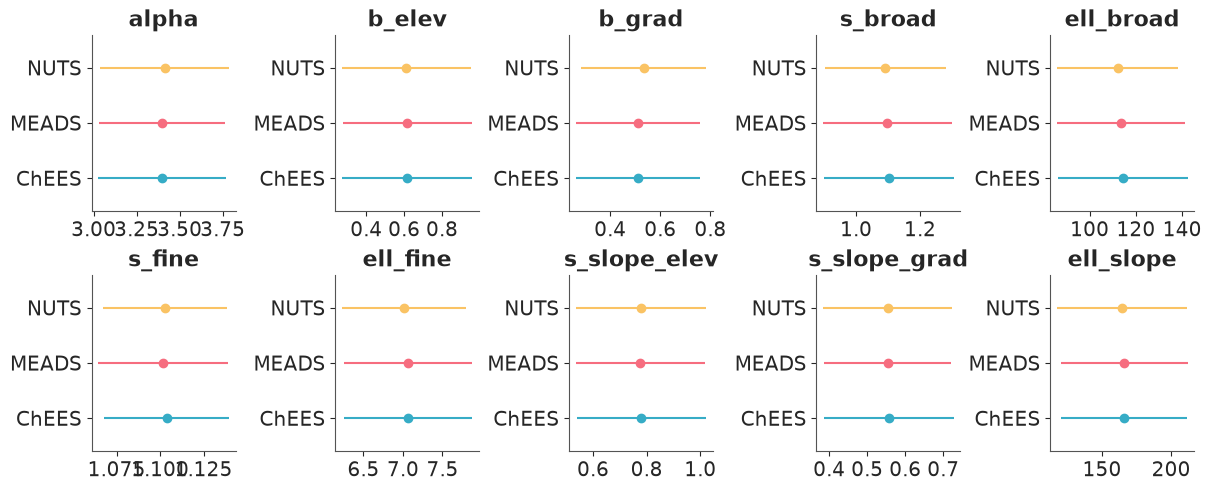

In [14]:
where = "GPU" if HAS_GPU else "CPU"
order = pd.DataFrame({
    f"ChEES ({where})": [stats_chees["warmup s"] + stats_chees["sampling s"], summary_chees.ess.min(), summary_chees.r_hat.max(), stats_chees["divergences"]],
    f"MEADS after ChEES ({where})": [stats_chees["warmup s"] + stats_chees["sampling s"] + stats_meads["warmup s"] + stats_meads["sampling s"], summary_meads.ess.min(), summary_meads.r_hat.max(), stats_meads["divergences"]],
    "NUTS, nutpie (CPU)": [nuts_wall, summary_nuts.ess.min(), summary_nuts.r_hat.max(), diverging],
}, index=["seconds", "worst ESS", "worst r_hat", "divergences"]).T
if HAS_GPU and CHAINS % 32 == 0 and np.isfinite(timing.loc[CHAINS, "CPU float32"]):
    # Same ESS, total GPU time scaled by a measured gradient-time ratio: estimates, not runs.
    gpu_ms = timing.loc[CHAINS, "GPU float32"]
    for label, cpu_ms in ((f"ChEES (CPU, one {CHAINS}-chain batch, estimated)", timing.loc[CHAINS, "CPU float32"]),
                          ("ChEES (CPU, 32-chain batches, estimated)", timing.loc[32, "CPU float32"] * CHAINS / 32)):
        order.loc[label] = order.loc[f"ChEES ({where})"]
        order.loc[label, "seconds"] *= cpu_ms / gpu_ms
order["worst ESS per second"] = order["worst ESS"] / order["seconds"]
order["ESS/s vs NUTS"] = order["worst ESS per second"] / order.loc["NUTS, nutpie (CPU)", "worst ESS per second"]
print(order.round(2).to_string())

fig, axes = plt.subplots(2, 5, figsize=(12, 4.8), layout="constrained")
for ax, name in zip(axes.flat, HYPER):
    for row, (label, s) in enumerate((("ChEES", summary_chees), ("MEADS", summary_meads), ("NUTS", summary_nuts))):
        ax.errorbar(s.loc[name, "mean"], row, xerr=s.loc[name, "sd"], fmt="o", color=f"C{row}")
    ax.set(title=name, yticks=[0, 1, 2], yticklabels=["ChEES", "MEADS", "NUTS"], ylim=(-0.6, 2.6))
    ax.locator_params(axis="x", nbins=4);

All three samplers agree on all ten hyperparameters, in a figure where ChEES and MEADS ran float32
on a GPU and nutpie ran float64 on a CPU, and that independent agreement is what lets us trust the
speed-up. In **worst-case ESS per second**, ChEES is about **55-70x** NUTS and MEADS about
**40-50x**, varying from run to run. Using 14 chains for nutpie, as measured above, would lower
those by about a fifth.

**The baseline is half the story.** An earlier version of this notebook quoted about 200x. It let
nutpie's chains fight over a BLAS thread pool and used only 4 chains. Nothing about the GPU
changed.

**Do not read that as the GPU alone, either.** The last two rows separate the effects. They scale
ChEES's total time by a measured gradient-time ratio, so they are estimates, not runs. As one
128-chain batch on the CPU, ChEES would take nearly two hours and match NUTS. In 32-chain batches,
the CPU's better regime, it would take about an hour and be about **2x** NUTS, assuming ESS and
adaptation hold. So the hardware gives roughly 25-30x and the algorithm roughly 2x. They also
depend on each other: the GPU's advantage exists only because the algorithm can use 128 chains in
lock-step. On the 20 m lattice, measured on 8 CPU cores without a GPU, nutpie simply wins: ChEES
reaches about 0.75x and MEADS about 0.5x of its ESS per second. MEADS's time here includes the
whole ChEES run it starts from.

Two limits. "Worst ESS" here is across ten hyperparameters, and says nothing about multimodal
posteriors, where every ensemble method can agree confidently on the wrong answer. And ESS per
second is not the whole cost: nutpie needed no culling, no metric options and no special priors.

## 8. Is single precision safe?

float32 resolves log densities of this size to about 0.004. HMC needs energy *differences* to be right, so we compare
directly, at posterior draws, against float64.

In [15]:
t0 = time.perf_counter()
with precision("float64"):
    model64, _, _ = make_model()
    f64, _, _, _ = jaxify(model64)
    flat = jnp.asarray(np.asarray(pos_chees[-1]), jnp.float64)
    lp64 = np.asarray(jax.vmap(f64)(flat))
    del model64, f64
lp32 = np.asarray(jax.vmap(logdensity)(pos_chees[-1]))
print(f"log density float32 - float64 at {CHAINS} posterior draws: mean {np.mean(lp32 - lp64):+.3f}, sd {np.std(lp32 - lp64):.3f}, largest {np.abs(lp32 - lp64).max():.3f}")

log density float32 - float64 at 128 posterior draws: mean -0.012, sd 0.039, largest 0.122


The error has an sd of about 0.04, and at most 0.1-0.15. A ChEES trajectory has an energy error of
order 1, so this is negligible for a sampler with long trajectories, and figure 4 agrees. It
matters more for MEADS's one-step test, where the energy differences are tiny, so we rely on the
agreement of the posteriors instead of on this number. Two warnings. float32 has no margin for
extreme states: a stuck chain in an earlier run had an error of 16.7, so a sudden jump here is a
symptom worth checking. And float32 on sums of millions of terms can fail outright, so repeat this
check whenever data grow.

## 9. Back to the forest

We have 30 snapshots of 128 chains. `jax.vmap` turns them into four 20,000-cell fields per draw, and post-processing is
one more thing a GPU does well.

3,840 draws of four (100, 200) fields in 1.5 s
expected total trees: 3,604 (observed 3,604)
elevation effect, west (200, 250) minus plateau (680, 150): mean 2.14, 90% interval 0.58 to 4.01, P(> 0) = 0.992


 block m  observed  fitted clumps 5%  fitted clumps 95%  new clumps 5%  new clumps 95%
     5.0      2.14              1.90               2.20           1.57            2.14
    10.0      4.18              3.64               4.47           2.57            4.26
    20.0      9.02              7.89               9.76           5.47            9.79
    50.0     24.11             22.30              26.97          17.34           32.29
   100.0     51.67             48.33              58.26          42.21           76.97


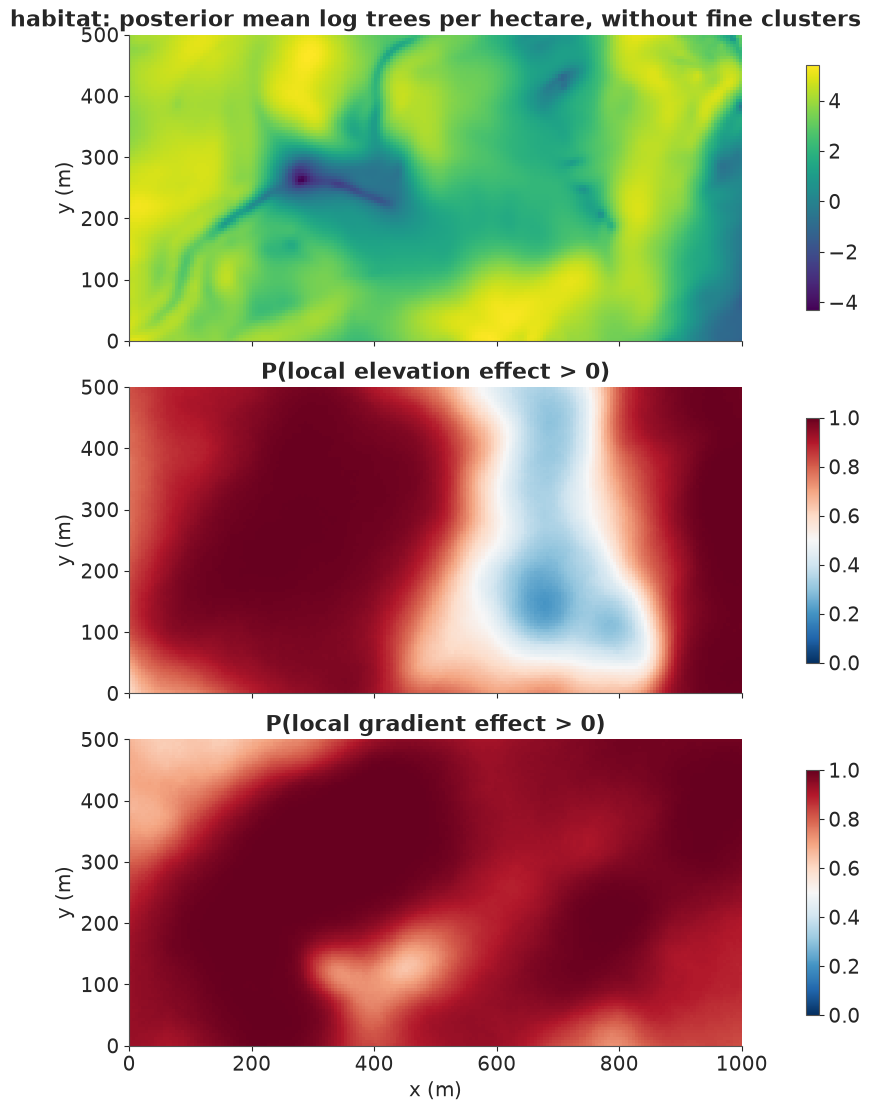

In [16]:
graph = get_jaxified_graph(inputs=model.value_vars, outputs=model.replace_rvs_by_values(list(outputs.values())))
fields = jax.jit(jax.vmap(lambda q: graph(*unravel(q))))
k_ha = int(100 / CELL)
ny_ha, nx_ha = y.shape[0] // k_ha, y.shape[1] // k_ha


def hectares(cellwise):
    n = cellwise.shape[0]
    return cellwise.reshape(n, ny_ha, k_ha, nx_ha, k_ha).sum((2, 4))


t0 = time.perf_counter()
sum_eta = sum_hab = 0.0
pos_elev, pos_grad = 0, 0
habitat_ha, contrast = [], []
sim_rng = np.random.default_rng(RANDOM_SEED)
cell_of = lambda x, y_m: (int(y_m / CELL), int(x / CELL))
WEST, PLATEAU = cell_of(200, 250), cell_of(680, 150)
for snapshot in pos_chees:
    eta, habitat, slope_elev, slope_grad = [np.asarray(a) for a in fields(snapshot)]
    sum_eta = sum_eta + np.exp(eta).sum(0)
    sum_hab = sum_hab + habitat.sum(0)
    pos_elev = pos_elev + (slope_elev > 0).sum(0)
    pos_grad = pos_grad + (slope_grad > 0).sum(0)
    habitat_ha.append(hectares(np.exp(habitat) * (CELL**2 / 1e4)))
    contrast.append(slope_elev[(slice(None), *WEST)] - slope_elev[(slice(None), *PLATEAU)])
n_draws = SNAPS * CHAINS
mean_lambda = sum_eta / n_draws
mean_habitat = sum_hab / n_draws
p_elev, p_grad = pos_elev / n_draws, pos_grad / n_draws
habitat_ha = np.concatenate(habitat_ha).reshape(n_draws, -1)
contrast = np.concatenate(contrast)
in_sample = sim_rng.poisson(np.exp(eta)).astype(float)   # the last snapshot: CHAINS independent draws
# In-sample replicates inherit the fitted clumps. A fair test draws NEW clumps: fresh z_fine, same hyperparameters.
z0 = NH + int(np.prod(M_SMOOTH))
z1 = z0 + int(np.prod(M_FINE))
key, k = jax.random.split(key)
fresh_clumps = pos_chees[-1].at[:, z0:z1].set(jax.random.normal(k, (CHAINS, z1 - z0), q0.dtype))
fresh = sim_rng.poisson(np.exp(np.asarray(fields(fresh_clumps)[0]))).astype(float)
postprocess_s = time.perf_counter() - t0
print(f"{n_draws:,} draws of four {y.shape} fields in {postprocess_s:.1f} s")
print(f"expected total trees: {mean_lambda.sum():,.0f} (observed {n_trees:,})")
print(f"elevation effect, west (200, 250) minus plateau (680, 150): mean {contrast.mean():.2f}, "
      f"90% interval {np.percentile(contrast, 5):.2f} to {np.percentile(contrast, 95):.2f}, P(> 0) = {(contrast > 0).mean():.3f}")

blocks = (1, 2, 4, 10, 20) if HAS_GPU else (1, 5)
ppc = pd.DataFrame({"block m": [b * CELL for b in blocks],
                    "observed": [vmr(y, b) for b in blocks],
                    "fitted clumps 5%": [np.percentile([vmr(r, b) for r in in_sample], 5) for b in blocks],
                    "fitted clumps 95%": [np.percentile([vmr(r, b) for r in in_sample], 95) for b in blocks],
                    "new clumps 5%": [np.percentile([vmr(r, b) for r in fresh], 5) for b in blocks],
                    "new clumps 95%": [np.percentile([vmr(r, b) for r in fresh], 95) for b in blocks]})
print(ppc.round(2).to_string(index=False))

fig, axes = plt.subplots(3, 1, figsize=(9, 11), sharex=True, layout="constrained")
panels = ((mean_habitat, "habitat: posterior mean log trees per hectare, without fine clusters", "viridis", {}),
          (p_elev, "P(local elevation effect > 0)", "RdBu_r", {"vmin": 0, "vmax": 1}),
          (p_grad, "P(local gradient effect > 0)", "RdBu_r", {"vmin": 0, "vmax": 1}))
for ax, (v, title, cmap, opts) in zip(axes, panels):
    im = ax.imshow(v, origin="lower", extent=extent, cmap=cmap, **opts)
    ax.set(title=title, ylabel="y (m)")
    fig.colorbar(im, ax=ax, shrink=0.8)
axes[2].set_xlabel("x (m)");

**The clustering check.** The table has two kinds of replicate. "Fitted clumps" keeps the fitted
fine field, which has one coefficient for nearly every cell, so its match to the data is close to
guaranteed: it is only an in-sample consistency check. "New clumps" keeps the hyperparameters and
draws a **fresh** fine field, which is the fair test. The observed ratio sits inside that interval
at scales from 20 to 100 m, and at or just past its upper end at 5 and 10 m, depending on the run.
So the model captures the clustering at most scales, and its clumps may be slightly too weak at
the finest. The expected total matches the 3,604 observed, as a log link with a free intercept
should give.

**To the first question: no, the terrain link does not hold everywhere.** Averaged over the plot,
the species prefers higher, steeper ground (`b_elev` about 0.6 and `b_grad` about 0.5, per sd of
elevation and of log gradient). But the middle map shows the elevation effect changing across the
plot. It is confidently positive over much of the west (roughly x = 100-450) and in the far east,
weaker along the western edge, and on the central plateau, around x = 700 m, it is not clearly
different from zero and may reverse. The printed contrast tests this directly: the effect at (200,
250) exceeds the effect at (680, 150) by about 2.1 (90% interval 0.5 to 4.0), with probability
about 0.99. The LogNormal prior excludes exactly zero variation, but a contrast this size comes
from the data. The elevation link is local. The gradient link is more general: probably positive
nearly everywhere, but confidently so over only about half the plot, and weakest around (450, 130)
and in the north-west.

These are associations in one census, not causes. Elevation here is also a proxy for drainage and
soil, and the `ell_slope` of about 165 m means that a feature much smaller than that cannot be
resolved.

**The fine clumps are strong.** `s_fine` is about 1.1 (a realised sd near 0.95) with a lengthscale
near 7 m, the footprint of a clump of siblings, which is why the habitat map above excludes them.
Now the survey.

share of the plot: P(elevation effect > 0) > 0.95: 39%, < 0.05: 0%
share of the plot: P(gradient effect > 0) > 0.95: 52%, < 0.05: 0%
 hectare  x m  y m  P(top 5)  habitat index  trees counted
       6  650   50      0.99     151.570007          226.0
      20   50  250      0.93     129.619995          210.0
      42  250  450      0.91     126.150002          247.0
       5  550   50      0.73     113.150002          181.0
      48  850  450      0.36      94.059998          134.0
top five by raw count: [5, 6, 20, 28, 42] - in common with the model's five: 4
hectare 28, raw top five only: 155 trees counted, habitat index 82, P(top 5) 0.13


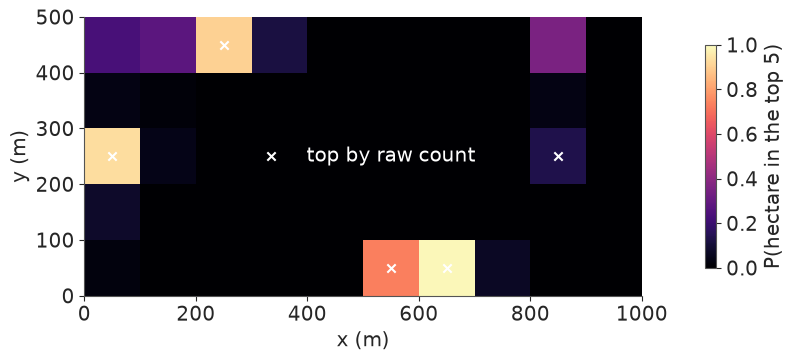

In [17]:
print(f"share of the plot: P(elevation effect > 0) > 0.95: {(p_elev > 0.95).mean():.0%}, < 0.05: {(p_elev < 0.05).mean():.0%}")
print(f"share of the plot: P(gradient effect > 0) > 0.95: {(p_grad > 0.95).mean():.0%}, < 0.05: {(p_grad < 0.05).mean():.0%}")
N_PICK = 5
ranks = (-habitat_ha).argsort(1).argsort(1)
p_top = (ranks < N_PICK).mean(0)
counts_ha = hectares(y[None])[0].ravel()
best = np.argsort(-p_top)[:N_PICK]
raw_best = np.argsort(-counts_ha)[:N_PICK]
table = pd.DataFrame({"hectare": best, "x m": (best % nx_ha) * 100 + 50, "y m": (best // nx_ha) * 100 + 50,
                      "P(top 5)": p_top[best], "habitat index": habitat_ha[:, best].mean(0), "trees counted": counts_ha[best]})
print(table.round(2).to_string(index=False))
print("top five by raw count:", sorted(raw_best.tolist()), "- in common with the model's five:", len(set(best) & set(raw_best)))
for h in sorted(set(raw_best) - set(best)):
    print(f"hectare {h}, raw top five only: {counts_ha[h]:.0f} trees counted, habitat index {habitat_ha[:, h].mean():.0f}, P(top 5) {p_top[h]:.2f}")

fig, ax = plt.subplots(figsize=(9, 3.5), layout="constrained")
im = ax.imshow(p_top.reshape(ny_ha, nx_ha), origin="lower", extent=extent, cmap="magma", vmin=0, vmax=1)
fig.colorbar(im, ax=ax, label=f"P(hectare in the top {N_PICK})", shrink=0.8)
ax.scatter((raw_best % nx_ha) * 100 + 50, (raw_best // nx_ha) * 100 + 50, marker="x", c="w", label="top by raw count")
ax.set(xlabel="x (m)", ylabel="y (m)")
ax.legend(loc="center", labelcolor="w", frameon=False);

Numbers first:

- **Elevation** is confidently positive over about 39% of the plot, and confidently negative
  nowhere. **Gradient** is confidently positive over about 52%, and confidently negative nowhere.

- We rank hectares by a **habitat index**: expected trees with the fine field set to zero, so that
  a hectare scores for its conditions and not for one lucky family of trees. The index sits well below the count of every hectare in the table, by a factor near 1.5-2. That is expected, and it does not mean the
  model discounts half the trees.

**Recommendation for the survey: hectares 6, 20, 42 and 5** (probabilities of being in the top
five of about 0.99, 0.93, 0.91 and 0.7), plus **hectare 48** as the fifth, with less confidence (about 0.35).

Four of the five match the raw top counts. The disagreement is the interesting part. Hectare 28,
near (850, 250), makes the raw top five but has a low model probability, 0.13 (the white cross on
a dark cell), and hectare 48 replaces it despite a lower count. Clumping is part of the reason:
42% of hectare 28's trees stand in three of its 25 squares of 20 m, against 31% in hectare 48. It
is not the whole reason, because hectare 42 is more clumped still (45%) and keeps its place. What
decides is the habitat estimate, which uses the terrain and the surroundings as well as the count:
an index of about 82 for hectare 28, on 155 counted, against 94 for hectare 48, on 134 counted.
The fifth place is genuinely uncertain, and hectares along the northern edge compete for it, so a
survey that can afford it should add a sixth.

## 10. Which steps does a GPU speed up?

In [18]:
t0 = time.perf_counter()
_ = summarise(kept_chees)
diagnostics_s = time.perf_counter() - t0
t0 = time.perf_counter()
_ = np.asarray(pos_chees[0])
transfer_s = (time.perf_counter() - t0) * SNAPS  # one snapshot, scaled up to all of them
stages = pd.Series({"warmup (ChEES)": stats_chees["warmup s"], "sampling (ChEES)": stats_chees["sampling s"],
                    "posterior fields": postprocess_s, "diagnostics, on the host": diagnostics_s,
                    "draws, GPU to host": transfer_s}, name="seconds")
print(stages.round(2).to_string())

warmup (ChEES)              112.96
sampling (ChEES)             24.63
posterior fields              1.48
diagnostics, on the host      0.15
draws, GPU to host            0.10


Almost all the time is warmup and sampling. Everything else, diagnostics included, takes seconds at most.

| step | GPU helps? | why, with this notebook's numbers |
|---|---|---|
| **Gradients, many chains, large arrays** | **Yes, by a lot** | more than 50x at 128 chains and 24,810 parameters |
| **Gradients, one chain, small model** | **No** | 0.5-0.8x at 1,578 parameters |
| **ChEES leapfrog steps** | Yes | 0.86 ms per gradient, the same as a bare gradient: no overhead |
| **NUTS tree building** | Partly | about 3.6 ms per gradient: bookkeeping cost, even with equal trees |
| **Warmup** | Yes, but it is the main cost | 85% of the ChEES run. A good start saves more than a faster GPU |
| **Posterior fields, predictions** | Yes | 3,840 draws of four 20,000-cell fields in about 1.5 s |
| **Diagnostics (r_hat, ESS)** | Not needed | a fraction of a second, on the CPU |
| **Moving draws to the host** | Not a bottleneck | a fraction of a second here; keep only what you need, as this adds up in memory |
| **Compilation** | Worse | 2 s against 0.4 s, and each new shape recompiles |
| **Python, I/O, data preparation** | No | not array arithmetic |

**Use a GPU for ensemble sampling when** the gradient is dominated by large array operations, the posterior is roughly
unimodal, and you can use float32 or have a data-centre card. **Stay with nutpie on a CPU when** the model is small,
is full of `scan` and control flow, or has modes that a shared tuning would hide, or if one reliable run in five
minutes already answers the question.

Four cautions from this notebook:

1. **An ensemble is only as healthy as its worst chain.** Shared tuning means one stuck chain can
   ruin everything. Look for stragglers. They caused the worst failures here.

2. **Healthy-looking numbers can be wrong.** Acceptance looked fine in both failures run above,
   and frozen MEADS chains had almost no divergences. Trust r_hat from dispersed starts, and
   per-chain plots.

3. **Check one result across seeds.** The first apparently successful MEADS run was luck. Only a
   test over several seeds exposed it.

4. **Give the baseline its best chance before quoting a speed-up.** Fixing one thread setting and
   using more chains cut this notebook's headline from about 200x to about 55-70x.

## Try it yourself

1. **Scale it up.** With a GPU, set `CHAINS` to 512 or 1024. (The CPU-estimate rows then drop out,
   as the CPU is not timed above 128 chains.) Does worst-case ESS per second keep rising, or does
   warmup, which does not get shorter, take over?
2. **Pay for precision.** Run ChEES in float64 inside `precision("float64")`. How close does the time come to the 17x
   penalty, and does the posterior change?
3. **Break it, then diagnose it.** Remove the culling step and run four or five seeds, printing `L` and the divergences
   each time. Then go back to `pm.HalfNormal` for the field sds and see what MEADS does.